# Lab 4 — Gas absorption and column height

Remove a dilute solute from a gas using a countercurrent solvent. Connect material balances, ideal stages, efficiency and a hydraulic screening calculation.

**Completed solution**

**Instructor solution — completed reference notebook.**

Prediction: increasing solvent flow reduces the ideal-stage requirement, but increases solvent handling. A larger equilibrium slope makes absorption less favourable and increases the minimum solvent requirement.

All exercises, including the small-change example and optional extension, are answered below. Use the matching `helpers.py` from this folder. Stage counts follow the student notebook conventions.

**Reading the answers:** The written interpretations refer to the printed default settings. Changing a setting updates calculated outputs when rerun, but does not automatically rewrite the prose. Alternative feasible choices can be valid when supported by evidence.

## Design workshop: run → compare → decide

All numerical methods, loops, tables and plots are supplied. You only change
values in cells marked **DESIGN SETTINGS** and write your engineering decisions.
In Colab, these settings also have parameter forms. The small worked examples
may be rerun after changing the named example values; their equations are supplied.
Run each analysis as provided; its implementation is collapsed where supported
and can be expanded if you are curious. No Python programming is assessed.

Work through the notebook in order. After changing an upstream setting, rerun
that section and every section below it so results stay consistent. Restore the
printed base values to reproduce the reference case. Keep at least one rejected
design and explain why you rejected it. Each analysis table is evidence for a
decision, not a complete answer on its own.

**Time budget (six hours):** setup and system prediction 30 min; balances and
feasibility 75 min; operating policy and checks 90 min; alternative designs
75 min; robustness and break 45 min; recommendation 45 min. The supplied
worked example belongs within the feasibility block, not an extra activity.

The core comparison block also includes a same-service cost/constraint challenge. These activities share the existing six-hour budget; prioritize one checked base case and the supplied comparison tables over extra sweeps.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [1]:
%matplotlib inline

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

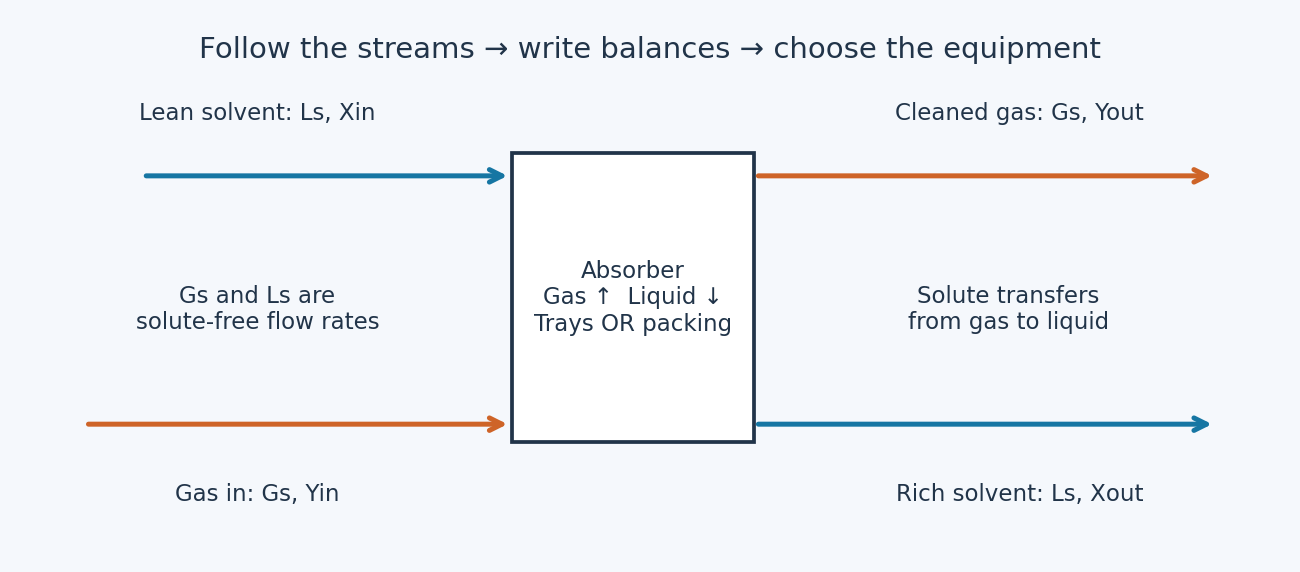

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions

Isothermal, dilute, nonreacting absorption with constant solute-free gas and solvent
flow rates $G_s,L_s$ (kmol/h). Use mole ratios $Y=y/(1-y)$ and $X=x/(1-x)$.
Assume the hypothetical equilibrium relation $Y^*=mX$, with $m=1.5$.
The operating line is $Y=Y_{out}+(L_s/G_s)(X-X_{in})$.
Balance: $L_s(X_{out}-X_{in})=G_s(Y_{in}-Y_{out})$.
For this linear case, $L_{min}/G_s=(Y_{in}-Y_{out})/(Y_{in}/m-X_{in})$.
Starting at $Y_1=Y_{out}$, equilibrium gives $X_n=Y_n/m$ and the balance gives
$Y_{n+1}=Y_{out}+(L_s/G_s)(X_n-X_{in})$. Stop once $Y_{n+1}\ge Y_{in}$.
Count the last stage in full. Ideal stages describe equilibrium contacts, not packing height.
For trays use an assumed overall efficiency; for packing use an independently supplied
HETP. Neither can be inferred from equilibrium data alone.

### Main-case input reference

Use the hypothetical isothermal, nonreacting system. Flows are solute-free molar
flows; X and Y are mole ratios, not mole fractions.

| Input | Value / units | Role |
| --- | --- | --- |
| Gs | 100 kmol carrier/h | Given gas-carrier flow |
| Yin | 0.030 mol solute/mol carrier | Given inlet ratio |
| Yout | 0.003 mol solute/mol carrier | Required outlet ratio |
| Xin | 0 mol solute/mol solvent | Fresh solvent assumption |
| Equilibrium slope m | 1.5, dimensionless | Assumed Y* = mX model parameter |
| Baseline Ls/Lmin | 1.5, dimensionless | Initial chosen solvent policy |

Minimum and selected solvent rates, rich-solvent ratio, removal and contact count
are calculated. HETP, tray efficiency, dry-bed properties, adverse equilibrium,
height limits and costs are separate supplied assumptions in later sections.
The smaller example has different solvent flow and gas-outlet target.

### Worked example: follow a solute through two contacts
Gas enters the bottom and solvent enters the top. Count contacts from the top,
where the clean-gas target and fresh-solvent composition are known.
For a small example use Gs = 100 kmol/h, Ls = 300 kmol/h, m = 1.5,
Xin = 0 and Yout = 0.002. The first equilibrium liquid ratio is 0.001333;
the next gas ratio is 0.006. Repeat the same two operations for contact two.

| Supplied example input | Value / units | Meaning / status |
| --- | --- | --- |
| Gs | 100 kmol/h | Given solute-free gas-carrier flow |
| Ls | 300 kmol/h | Chosen solute-free solvent flow |
| Equilibrium slope m | 1.5, dimensionless | Assumed linear model Y* = mX; synthetic |
| Lean solvent Xin | 0 mol solute/mol solvent | Fresh solvent assumption |
| Clean gas Yout | 0.002 mol solute/mol carrier | Required outlet mole ratio |

X = x/(1−x) and Y = y/(1−y) are **mole ratios**, not mole fractions.
Assume isothermal, nonreacting absorption with constant solute-free flow rates.
The first two contacts are calculated demonstrations, not a specified total
column height or number of contacts. The later Yin = 0.03 is the inlet target
for the small-change exercise, not an extra condition used in these first two steps.

Contact 1: X = 0.001333; next Y = 0.006000
Contact 2: X = 0.004000; next Y = 0.014000


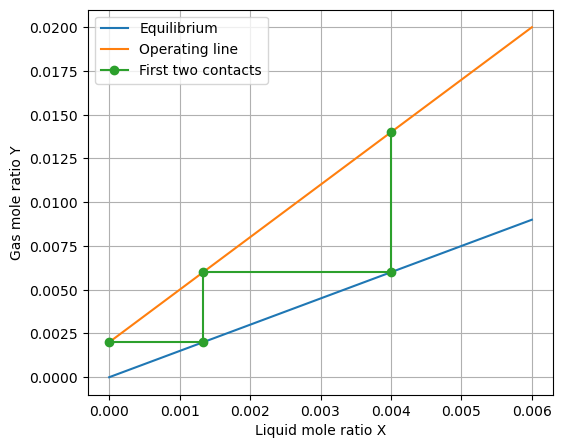

In [3]:
ex_G, ex_L, ex_m = 100.0, 300.0, 1.5
ex_Xin, ex_Yout = 0.0, 0.002
ex_y = ex_Yout
ex_points = [(ex_Xin, ex_y)]
for ex_n in range(1, 3):
    ex_x = ex_y / ex_m  # horizontal move to equilibrium
    ex_points.append((ex_x, ex_y))
    ex_y = ex_Yout + ex_L/ex_G * (ex_x-ex_Xin)  # vertical to operating line
    ex_points.append((ex_x, ex_y))
    print(f"Contact {ex_n}: X = {ex_x:.6f}; next Y = {ex_y:.6f}")
ex_grid = np.linspace(0, 0.006, 100)
plt.figure(figsize=(6, 5))
plt.plot(ex_grid, ex_m*ex_grid, label="Equilibrium")
plt.plot(ex_grid, ex_Yout+ex_L/ex_G*(ex_grid-ex_Xin), label="Operating line")
ex_steps = np.array(ex_points)
plt.plot(ex_steps[:, 0], ex_steps[:, 1], "o-", label="First two contacts")
plt.xlabel("Liquid mole ratio X"); plt.ylabel("Gas mole ratio Y")
plt.legend(); plt.grid(); plt.show()

**Try a small change:** Change Ls from 300 to 400 kmol/h. Does each step cover more or less of the required gas-composition change? The supplied main-case analysis counts all required contacts; explain why checking minimum solvent flow comes first.

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Solution to the small change

The higher solvent rate gives a larger rise in Y per contact when stepping from top to bottom. Both small cases reach Yin = 0.03 within three full contacts, although their intermediate compositions differ.

In [4]:
for warm_L in [300.,400.]:
    warm_min = 100*(.03-.002)/(.03/1.5)
    assert warm_L > warm_min
    warm_y, warm_n = .002, 0
    while warm_y < .03:
        if warm_n >= 300:
            raise ValueError('Small-example stage cap')
        warm_x = warm_y/1.5
        warm_next = .002+warm_L/100*warm_x
        if warm_next <= warm_y:
            raise ValueError('Non-progressing stage')
        warm_n += 1
        print(f"Ls={warm_L:.0f}, contact={warm_n}, X={warm_x:.6f}, next Y={warm_next:.6f}")
        warm_y = warm_next

Ls=300, contact=1, X=0.001333, next Y=0.006000
Ls=300, contact=2, X=0.004000, next Y=0.014000
Ls=300, contact=3, X=0.009333, next Y=0.030000
Ls=400, contact=1, X=0.001333, next Y=0.007333
Ls=400, contact=2, X=0.004889, next Y=0.021556
Ls=400, contact=3, X=0.014370, next Y=0.059481


### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

Minimum solvent: 135.00 kmol/h; selected: 202.50 kmol/h


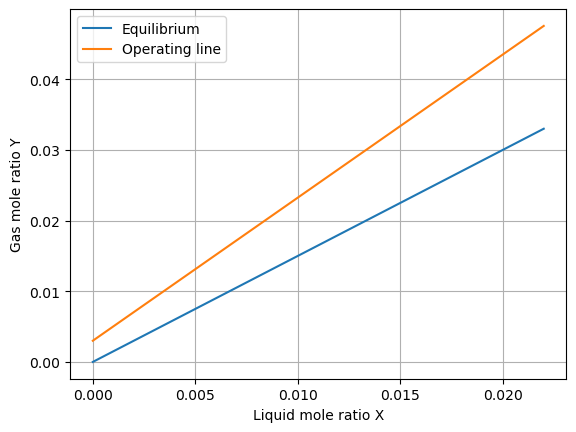

In [5]:
Gs, Yin, Yout, Xin, m = 100.0, 0.03, 0.003, 0.0, 1.5
Lmin = Gs*(Yin-Yout)/(Yin/m-Xin)
Ls = 1.5*Lmin
Xout = Xin + Gs/Ls*(Yin-Yout)
print(f"Minimum solvent: {Lmin:.2f} kmol/h; selected: {Ls:.2f} kmol/h")
X = np.linspace(0, Yin/m*1.1, 200)
plt.plot(X, m*X, label="Equilibrium")
plt.plot(X, Yout+Ls/Gs*(X-Xin), label="Operating line")
plt.xlabel("Liquid mole ratio X"); plt.ylabel("Gas mole ratio Y")
plt.legend(); plt.grid()

## 2. Check removal duty and solvent feasibility — 75 minutes

Run the supplied solute balance and pinch construction. Check the
removed solute flow with a calculator. Explain why mole ratios are used with
solute-free flow rates. Identify both end driving forces on the diagram and
decide whether the selected solvent rate is feasible. Report removal, rich
solvent composition and minimum solvent rate.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

Gas inlet mole fraction=0.029126; outlet=0.002991
Solvent outlet X=0.013333; x=0.013158
Solute removed=2.700000 kmol/h (90.0% of entering solute)
Solute-balance residual=4.441e-16 kmol/h
Top driving force=0.003000; bottom=0.010000; Lmin=135.000 kmol/h


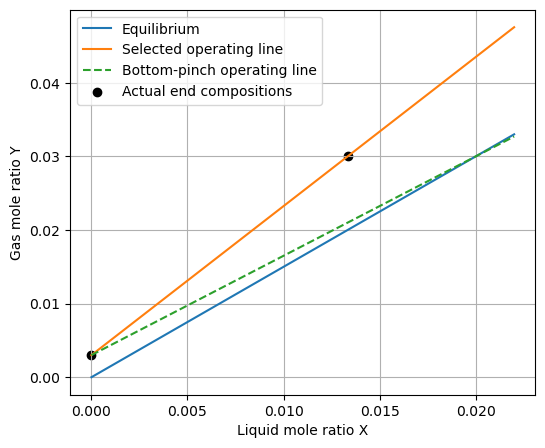

In [6]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
yin_fraction, yout_fraction = Yin/(1+Yin), Yout/(1+Yout)
xout_ratio = Xin+Gs/Ls*(Yin-Yout)
xout_fraction = xout_ratio/(1+xout_ratio)
removed = Gs*(Yin-Yout)
liquid_gain = Ls*(xout_ratio-Xin)
gas_reduction_percent = (Yin-Yout)/Yin*100
top_force = Yout-m*Xin
bottom_force = Yin-m*xout_ratio
derived_Lmin = Gs*(Yin-Yout)/(Yin/m-Xin)
assert np.isclose(removed,liquid_gain)
assert np.isclose(derived_Lmin,Lmin)
assert min(top_force,bottom_force)>0
print(f"Gas inlet mole fraction={yin_fraction:.6f}; outlet={yout_fraction:.6f}")
print(f"Solvent outlet X={xout_ratio:.6f}; x={xout_fraction:.6f}")
print(f"Solute removed={removed:.6f} kmol/h ({gas_reduction_percent:.1f}% of entering solute)")
print(f"Solute-balance residual={removed-liquid_gain:.3e} kmol/h")
print(f"Top driving force={top_force:.6f}; bottom={bottom_force:.6f}; Lmin={derived_Lmin:.3f} kmol/h")
plt.figure(figsize=(6,5))
plt.plot(X,m*X,label='Equilibrium')
plt.plot(X,Yout+Ls/Gs*(X-Xin),label='Selected operating line')
plt.plot(X,Yout+Lmin/Gs*(X-Xin),'--',label='Bottom-pinch operating line')
plt.scatter([Xin,xout_ratio],[Yout,Yin],color='black',label='Actual end compositions')
plt.xlabel('Liquid mole ratio X'); plt.ylabel('Gas mole ratio Y')
plt.legend(); plt.grid(); plt.show()

**Answers to the design questions — default settings**


**Removal and basis check.** Incoming solute is $G_sY_{in}=100(0.03)=3$
kmol/h; outgoing solute is $100(0.003)=0.3$ kmol/h. Removal is therefore
2.7 kmol/h, or 90%. The solvent gains the same amount. Using mole ratios
with solute-free flows keeps the carrier and solvent basis constant even
though total mixture flows change as solute transfers.

**Compositions.** Gas mole fractions are approximately 0.029126 in and
0.002991 out. The rich-solvent ratio is Xout = 0.0133333, or a mole
fraction of 0.0131579. Ratios and fractions must not be interchanged in
the operating-line equations.

**Driving forces and feasibility.** At the top, compare the outgoing gas
with equilibrium over entering solvent: $Yout-mXin=0.003$. At the bottom,
compare incoming gas with equilibrium over rich solvent:
$Yin-mXout=0.010$. Both are positive. At the limiting bottom pinch,
$Xout=Yin/m$; substituting into the balance gives Lmin = 135 kmol/h.
The selected 202.5 kmol/h is 1.5 times this limit. It is feasible in the
linear equilibrium model, but this does not yet verify transfer rate,
wet hydraulics or real solvent capacity.

## 3. Choose a solvent rate — 90 minutes

Choose a solvent rate as a multiple of the minimum and run the
supplied staircase and solvent sweep. No recurrence or loop needs to be written.
Compare your choice with a lower and a higher rate. Recommend a provisional
solvent policy using contact count, solvent handling and margin above the pinch.
State which missing regeneration or operating-cost information could change
your decision. Explain how the final full-contact convention affects the count.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [7]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# Ls/Lmin; keep above 1
solvent_multiple = 1.5 #@param {type:"number"}

Full ideal contacts=5; absorption factor=1.3500


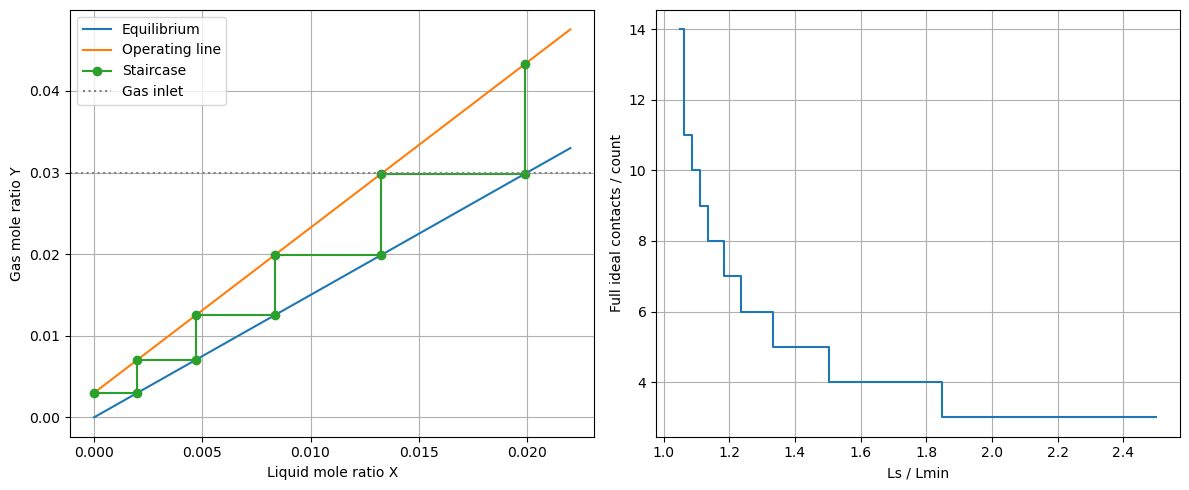

Expected pinch rejection: Solvent flow at or below minimum


In [8]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
Ls = solvent_multiple*Lmin
Xout = Xin+Gs/Ls*(Yin-Yout)
def absorption_steps(gas,liquid,gas_in,gas_out,liquid_in=0.,eq_slope=1.5,limit=300):
    if min(gas,liquid,eq_slope)<=0 or liquid_in<0:
        raise ValueError('Invalid flow, slope or solvent composition')
    if not gas_in>gas_out>eq_slope*liquid_in:
        raise ValueError('Infeasible absorption direction')
    minimum = gas*(gas_in-gas_out)/(gas_in/eq_slope-liquid_in)
    if liquid<=minimum:
        raise ValueError('Solvent flow at or below minimum')
    y_value = gas_out
    steps = [(liquid_in,y_value)]
    for n in range(1,limit+1):
        x_value = y_value/eq_slope
        steps.append((x_value,y_value))
        next_y = gas_out+liquid/gas*(x_value-liquid_in)
        steps.append((x_value,next_y))
        if next_y>=gas_in:
            return n,np.array(steps)
        if next_y<=y_value+1e-12:
            raise ValueError('Pinch or non-progressing stage')
        y_value = next_y
    raise ValueError('Stage cap reached')

N_abs,abs_steps = absorption_steps(Gs,Ls,Yin,Yout,Xin,m)
assert N_abs==h.stage_count(Gs,Ls,Yin,Yout,Xin,m)[0]
# Independent fresh-solvent geometric-series check.
absorption_factor = Ls/(m*Gs)
analytic_n = next(n for n in range(1,301)
                  if Yout*sum(absorption_factor**k for k in range(n+1))>=Yin)
assert analytic_n==N_abs
print(f'Full ideal contacts={N_abs}; absorption factor={absorption_factor:.4f}')
solvent_ratios = np.linspace(1.05,2.5,60)
abs_counts = [absorption_steps(Gs,r*Lmin,Yin,Yout,Xin,m)[0] for r in solvent_ratios]
fig,axes = plt.subplots(1,2,figsize=(12,5))
axes[0].plot(X,m*X,label='Equilibrium')
axes[0].plot(X,Yout+Ls/Gs*(X-Xin),label='Operating line')
axes[0].plot(abs_steps[:,0],abs_steps[:,1],'o-',label='Staircase')
axes[0].axhline(Yin,color='grey',linestyle=':',label='Gas inlet')
axes[0].set(xlabel='Liquid mole ratio X',ylabel='Gas mole ratio Y'); axes[0].legend()
axes[1].step(solvent_ratios,abs_counts,where='mid')
axes[1].set(xlabel='Ls / Lmin',ylabel='Full ideal contacts / count')
for axis in axes:
    axis.grid()
plt.tight_layout(); plt.show()
try:
    absorption_steps(Gs,Lmin,Yin,Yout,Xin,m)
except ValueError as error:
    print('Expected pinch rejection:',error)
else:
    raise AssertionError('Minimum solvent rate should be rejected')

**Answers to the design questions — default settings**


**Solvent-policy comparison.** At L/Lmin = 1.1, 1.5 and 2.0, the solvent
rates are 148.5, 202.5 and 270 kmol/h and the calculated requirements are
ten, five and three full ideal contacts respectively. These alternatives
illustrate why approaching the pinch saves solvent at the expense of
height, while more solvent reduces contacts but increases handling.

**Provisional choice.** I retain L/Lmin = 1.5 as a starting point:
five contacts at a rate 50% above the nominal minimum. This is a margin
relative to an equilibrium limit, not a flooding or safety margin. The
1.1 option is less attractive if equilibrium is uncertain; the 2.0 option
could be justified by a strict height constraint but needs a circulation
and cost assessment.

**What could change the choice?** Solvent price, regeneration heat,
recovery/recycle requirements, liquid pumping and distribution, wet pressure
drop, packing/tray cost and available vessel height could favour a different
policy. None is quantified by the equilibrium staircase.

**Final full-contact convention.** Stepping from the known top conditions,
the last vertical move reaches or exceeds Yin. Keeping the entire final
contact rounds the requirement upward rather than interpolating a partial
one. That convention explains a conservative integer count; it does not
ensure the same margin against uncertainty in equilibrium or efficiency.

## 4. Compare internals and screen hydraulics — 75 minutes

Compare tray and packing active heights using the supplied results.
Choose a provisional internals option or explain why selection must wait.
Report the range of packed height and the dry-bed pressure-drop estimate.
Would you use that dry estimate to approve an irrigated absorber? Identify
the missing physical effects and data. Do not apply tray efficiency to a
packing height already based on HETP.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

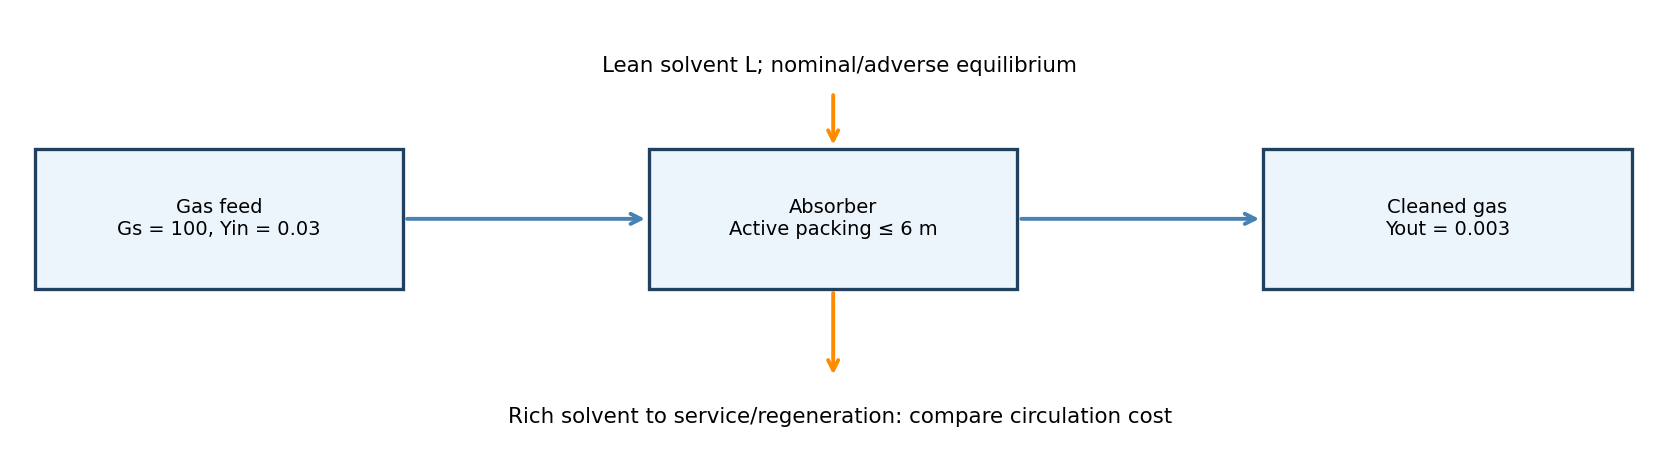

Block diagram of the design boundary; see the main flowsheet for physical stream connections.


**Core design challenge — a height-limited absorber under uncertainty.** Retain
the same 100 kmol/h solute-free gas feed and **90% removal**. Compare solvent
rates of 1.1, 1.5, 1.8, 2.0 and 2.5 times the nominal minimum of 135 kmol/h.
Screen each at both nominal m = 1.5 and adverse m = 1.8. Use conservative
HETP = 1.2 m and **maximum active packed height 6 m**. This is a height
constraint, not a verified wet-hydraulic capacity.

Illustrative installed packing-section cost is €20000 + €6000 per metre of
required active height. Annual solvent-service cost is €60 per (kmol/h) of
circulation at 4000 h/year. This is a supplied combined service allowance,
not solvent purchase cost or a calculated regeneration duty. Compare ten-year
undiscounted totals. Missing wet hydraulics, internals and maintenance still matter.

Choose a feasible solvent/height combination. Does the nominal five-contact
choice fit the adverse condition? Is the lowest solvent rate actually feasible?
Would minimum height also minimize this cost model? Explain how HETP uncertainty
can change the answer and what extra cost or vendor data would change your choice.


In [9]:
#@title DESIGN SETTINGS — edit values or use the Colab form
absorber_tray_efficiency = 0.60 #@param {type:"number"}
# m
absorber_tray_spacing = 0.45 #@param {type:"number"}
# m
hetp_low = 0.6 #@param {type:"number"}
# m
hetp_high = 1.2 #@param {type:"number"}
robust_slope = 1.8 #@param {type:"number"}
design_hetp = 1.2 #@param {type:"number"}
solvent_service_price = 60.0 #@param {type:"number"}

Tray option: 9 trays, active height=4.05 m
Packing option: active height=3.00–6.00 m
Superficial gas velocity=0.800 m/s
Dry Ergun gradient=47.927230 Pa/m; dry drop=143.78–287.56 Pa


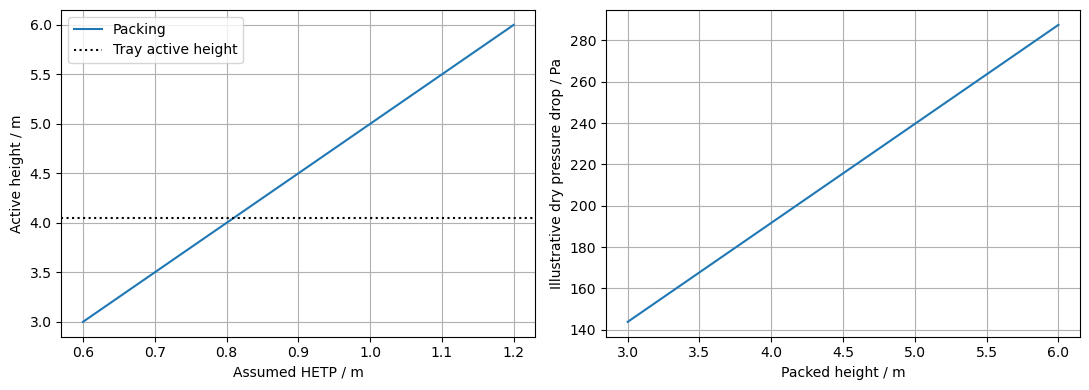

L/Lmin   L/kmol/h nominal N adverse N height/m horizon/€ eligible / reason
  1.10      148.5        10       nan      nan       nan False / equilibrium pinch
  1.50      202.5         5         6     7.20    184700 False / height limit
  1.80      243.0         4         5     6.00    201800 True / OK
  2.00      270.0         3         4     4.80    210800 True / OK
  2.50      337.5         3         3     3.60    244100 True / OK
Selected robust cost candidate: {'multiple': 1.8, 'solvent': 243.0, 'nominal': 4, 'worst': 5, 'height': 6.0, 'total': 201800.0, 'feasible': True, 'reason': 'OK'}


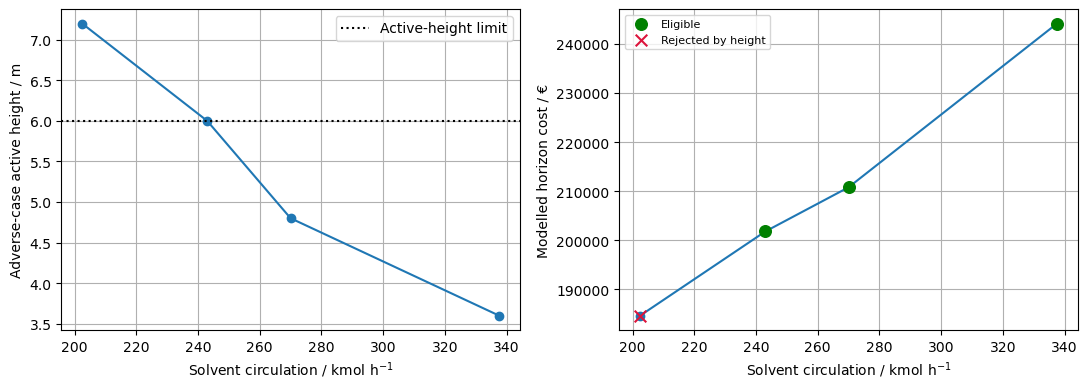

In [10]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
installed_trays = int(np.ceil(N_abs/absorber_tray_efficiency))
tray_height = installed_trays*absorber_tray_spacing
hetp_values = np.linspace(hetp_low,hetp_high,25)
packed_heights = N_abs*hetp_values
cross_section, gas_volume = 1.,.8
superficial_velocity = gas_volume/cross_section
dry_gradient = h.ergun_gradient(superficial_velocity,.70,.025,1.2,1.8e-5)
dry_pressure_drop = dry_gradient*packed_heights
print(f'Tray option: {installed_trays} trays, active height={tray_height:.2f} m')
print(f'Packing option: active height={packed_heights.min():.2f}–{packed_heights.max():.2f} m')
print(f'Superficial gas velocity={superficial_velocity:.3f} m/s')
print(f'Dry Ergun gradient={dry_gradient:.6f} Pa/m; dry drop={dry_pressure_drop.min():.2f}–{dry_pressure_drop.max():.2f} Pa')
assert np.isclose(h.ergun_gradient(0,.70,.025),0)
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hetp_values,packed_heights,label='Packing')
axes[0].axhline(tray_height,linestyle=':',color='black',label='Tray active height'); axes[0].legend()
axes[0].set(xlabel='Assumed HETP / m',ylabel='Active height / m')
axes[1].plot(packed_heights,dry_pressure_drop)
axes[1].set(xlabel='Packed height / m',ylabel='Illustrative dry pressure drop / Pa')
for axis in axes:
    axis.grid()
plt.tight_layout(); plt.show()


# Same removal; choose solvent and height against adverse equilibrium.
absorber_designs = h.compare_designs(robust_slope,design_hetp,solvent_service_price)
print('L/Lmin   L/kmol/h nominal N adverse N height/m horizon/€ eligible / reason')
for row in absorber_designs:
    print(f"{row['multiple']:6.2f} {row['solvent']:10.1f} {row['nominal']:9d} {row['worst']:9.0f} {row['height']:8.2f} {row['total']:9.0f} {row['feasible']} / {row['reason']}")
eligible_absorbers = [r for r in absorber_designs if r['feasible']]
absorber_best = min(eligible_absorbers,key=lambda r:r['total']) if eligible_absorbers else None
print('Selected robust cost candidate:',absorber_best)
fig,axes = plt.subplots(1,2,figsize=(11,4))
valid = [r for r in absorber_designs if np.isfinite(r['height'])]
axes[0].plot([r['solvent'] for r in valid],[r['height'] for r in valid],'o-')
axes[0].axhline(6,color='black',linestyle=':',label='Active-height limit'); axes[0].legend()
axes[0].set(xlabel='Solvent circulation / kmol h$^{-1}$',ylabel='Adverse-case active height / m')
axes[1].plot([r['solvent'] for r in valid],[r['total'] for r in valid],'o-')
for ok,color,marker,label in [(True,'green','o','Eligible'),(False,'crimson','x','Rejected by height')]:
    subset = [r for r in valid if r['feasible']==ok]
    axes[1].scatter([r['solvent'] for r in subset],[r['total'] for r in subset],color=color,marker=marker,s=70,label=label,zorder=3)
axes[1].legend(fontsize=8)
axes[1].set(xlabel='Solvent circulation / kmol h$^{-1}$',ylabel='Modelled horizon cost / €')
for axis in axes: axis.grid()
plt.tight_layout(); plt.show()


**Answers to the design questions — default settings**


**Height comparison.** Five ideal contacts at overall tray efficiency 0.60
give nine actual trays, hence 4.05 m active height. Independently, HETP
of 0.6–1.2 m gives 3–6 m active packed height. These ranges overlap,
so height alone does not establish a preferred internals type. I would
defer final selection until capacity, wet pressure drop, distribution,
fouling tendency, maintenance and transfer-performance data are available.

**Hydraulic screening numbers.** The illustrative area of 1 m² and gas
flow of 0.8 m³/s give 0.8 m/s superficial velocity. The dry Ergun model
predicts 47.927 Pa/m, or about 144–288 Pa over the 3–6 m packed height.
Distributor and other internal losses are not included.

**Would this approve an irrigated absorber?** No. The dry equivalent-particle
model does not represent liquid holdup, wetted effective area, packing
shape, countercurrent loading or flooding. Obtain packing-specific wet
pressure-drop and capacity curves at the actual gas/liquid properties and
loads. The supplied cross-sectional area is an assumed screening input,
not a hydraulically selected column diameter.

**Why not multiply packing height by tray inefficiency too?** HETP already
converts ideal stages to packed height. Overall tray efficiency is a
different equipment model for actual tray count. Applying both would mix
two alternative conversions without a physical basis.



**Core challenge: the nominal candidate does not pass the robust height screen.**
At L = 148.5 kmol/h, the adverse minimum is 162 kmol/h, so the lowest
circulation policy is infeasible even with unlimited height. At 202.5 kmol/h,
absorption remains possible, but six adverse-case contacts require 7.2 m
at HETP = 1.2 m and exceed the 6 m active-height limit.

**Selected design.** At **243 kmol/h**, or 1.8 times nominal Lmin, the
model gives four nominal and five adverse-case contacts. Conservative packed
height is 6.0 m and the illustrative ten-year total is **€201800**. It is
the least-cost eligible candidate in the supplied table. At 270 kmol/h,
height falls to 4.8 m but total cost rises to €210800. At 337.5 kmol/h,
height is only 3.6 m, but total cost is €244100. Minimum height therefore
does not minimize this cost model: additional solvent service can outweigh
the installed-height saving.

**Margin and evidence.** The selected 6 m height exactly meets the assumed
limit; it has no additional allowance for worse HETP, equilibrium or distribution.
If the actual HETP exceeds 1.2 m, this selection may fail, and a higher solvent
rate or revised geometry may be needed. Obtain packing-specific transfer data
and wet capacity/pressure-drop curves before accepting it. The annual service
allowance is an assumed circulation-cost model, not a prediction of regeneration
heat or a wet hydraulic assessment. The nominal five-contact baseline is useful
for comparison but is not the final robust candidate under these new constraints.

## 5. Check the recommendation against equilibrium uncertainty — 45 minutes

Take a 10-minute break. Run the ±20% equilibrium-slope cases at your
fixed selected solvent flow. Determine whether each is feasible before reading
its stage count. Does your nominal height have adequate margin? Decide whether
to increase solvent flow, allow more height or obtain better equilibrium data.
List vendor data needed for wet pressure drop, liquid distribution and flooding
margin; explain why the dry Ergun result cannot supply them.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

Distinguish the original solvent-policy sensitivity from the robust candidate in the preceding core comparison. State whether you retain or revise the original policy after applying the height limit.

m       Lmin/kmol h-1   Ls/Lmin   full contacts   status
1.200      108.000    1.875        3       feasible
1.500      135.000    1.500        5       feasible
1.800      162.000    1.250        6       feasible
Extra case: m=2.5, Lmin=225.00, feasible=False


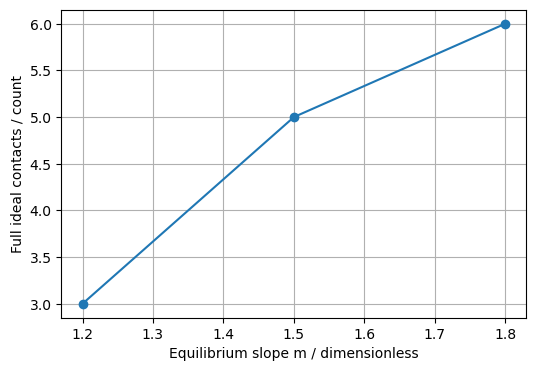

In [11]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
robustness = []
print('m       Lmin/kmol h-1   Ls/Lmin   full contacts   status')
for candidate_m in [.8*m,m,1.2*m]:
    candidate_min = Gs*(Yin-Yout)/(Yin/candidate_m-Xin)
    if Ls<=candidate_min:
        robustness.append((candidate_m,candidate_min,np.nan))
        print(f'{candidate_m:.3f}   {candidate_min:10.3f}    {Ls/candidate_min:.3f}       --       infeasible')
        continue
    candidate_N = absorption_steps(Gs,Ls,Yin,Yout,Xin,candidate_m)[0]
    robustness.append((candidate_m,candidate_min,candidate_N))
    print(f'{candidate_m:.3f}   {candidate_min:10.3f}    {Ls/candidate_min:.3f}       {candidate_N:2d}       feasible')
# Also show that the same fixed-flow calculation rejects a true infeasible case.
infeasible_m = 2.5
infeasible_min = Gs*(Yin-Yout)/(Yin/infeasible_m-Xin)
print(f"Extra case: m={infeasible_m}, Lmin={infeasible_min:.2f}, feasible={Ls>infeasible_min}")
robust_array = np.array(robustness)
plt.figure(figsize=(6,4))
plt.plot(robust_array[:,0],robust_array[:,2],'o-')
plt.xlabel('Equilibrium slope m / dimensionless'); plt.ylabel('Full ideal contacts / count')
plt.grid(); plt.show()

**Answers to the design questions — default settings**


**Requested uncertainty cases.** At m = 1.2, 1.5 and 1.8, the minimum
solvent rates are 108, 135 and 162 kmol/h. At fixed L = 202.5 kmol/h,
all are feasible, but the full-contact counts are three, five and six.
At the adverse slope the nominal 50% solvent excess over minimum shrinks
to 25%. Feasibility alone therefore does not demonstrate adequate height.

**Does the nominal height have enough margin?** A design based strictly
on five contacts does not cover the six-contact adverse case at unchanged
performance assumptions. Trays would increase from nine to ten actual
trays (4.05 to 4.50 m active height). At the same HETP, packed height
would rise by 20%, giving 3.6–7.2 m across the stated HETP range. Do
not interpret the nominal upper value of 6 m as automatically sufficient
when both equilibrium and HETP may be adverse.

**Decision.** Before fixing a new vessel, obtain better equilibrium data
and carry the six-contact case in the preliminary height allowance.
Alternatively, increasing solvent to 243 kmol/h at m = 1.8 preserves
the nominal absorption factor and restores five contacts in this model.
That option needs wet-hydraulic and solvent-cost checks before adoption.

**Vendor evidence needed.** Request wet loading/flooding curves, recommended
capacity margins, liquid distributor operating limits, holdup and packing-
specific transfer data. Dry Ergun contains none of these relationships.
The conditional response should therefore address both equilibrium margin
and actual equipment performance, rather than simply increasing a dry
pressure-drop allowance.

### Numerical support for the reference comparisons

These extra calculations reproduce the alternative cases discussed in the answers. They use explicit reference settings.

In [12]:
# Supporting comparison for the written default-case answers.
print("Reference comparison at m=1.5 and Lmin=135 kmol/h")
for comparison_multiple in [1.1,1.5,2.0]:
    comparison_L = comparison_multiple*135
    comparison_N = absorption_steps(100,comparison_L,.03,.003,0,1.5)[0]
    print(f"L/Lmin={comparison_multiple:.1f}: L={comparison_L:.1f} kmol/h; {comparison_N} full contacts")
assert absorption_steps(100,243,.03,.003,0,1.8)[0] == 5
print("Adverse m=1.8, increased L=243 kmol/h: 5 full contacts")

Reference comparison at m=1.5 and Lmin=135 kmol/h
L/Lmin=1.1: L=148.5 kmol/h; 10 full contacts
L/Lmin=1.5: L=202.5 kmol/h; 5 full contacts
L/Lmin=2.0: L=270.0 kmol/h; 3 full contacts
Adverse m=1.8, increased L=243 kmol/h: 5 full contacts


## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

**Design-review checklist:** Does your selected design meet every stated
requirement? Include its operating margin, one rejected alternative and a
numerical reason for rejection. Distinguish a model verification check from
evidence that real equipment will perform as predicted. Identify the next
measurement or vendor datum needed. No new code is required for submission.

Include your choice from the core cost/constraint table, a rejected alternative and the effect of the changed duty or adverse condition. Identify both the energy/circulation criterion and the cost criterion.

### Example engineering recommendation

For the added robust-height challenge, I recommend
243 kmol/h solvent, or 1.8 times the nominal minimum, as the preferred
candidate for review. It needs four nominal and five adverse-case contacts,
giving 6 m active packed height at HETP = 1.2 m and an illustrative
ten-year total of €201800. This exactly meets the height limit and needs
vendor validation; it is not a margin beyond that limit. The original
202.5 kmol/h baseline fails the adverse height screen. The following nominal
balance and tray/packing comparisons describe that original baseline, not a
claim that its height satisfies the new robust requirement.

The removed solute is 2.7 kmol/h, matching the calculated liquid gain.
The rich-solvent outlet ratio is 0.0133333, equivalent to a mole fraction
of 0.0131579. Both terminal driving forces are positive. The independently
implemented recurrence agrees with the helper and with the fresh-solvent
geometric-series result. The last stage is counted in full even when its
step overshoots the specified gas-inlet ratio, consistent with the lab's
integer counting rule.

For the tray option, an overall efficiency of 0.60 gives nine installed
trays and 4.05 m active height using the stated spacing. For the packing
option, an assumed HETP of 0.6–1.2 m gives 3–6 m active height. These
are alternative equipment models; tray efficiency should not be applied
on top of HETP. The information supplied does not justify choosing one
internals type on economic or hydraulic grounds.

The dry-bed calculation gives about 47.93 Pa/m at 0.8 m/s superficial
gas velocity. It demonstrates how geometry and gas flow enter an Ergun
screening calculation, but cannot establish wet operating pressure drop
or flooding margin. Liquid loading, holdup, distributor performance and
actual packing geometry are absent.

The equilibrium-slope sensitivity remains feasible across the requested
range, although the contact requirement changes. Increasing solvent flow
could reduce contacts, but it would also raise circulation and possible
regeneration demand. Before fixing height or diameter, obtain validated
equilibrium data at operating conditions and assess heat effects. Obtain
vendor capacity and wet pressure-drop correlations, packing-specific
mass-transfer performance or HETP, and tray-efficiency data if trays remain
an option. A complete design must also include distributors, disengagement
space, hydraulic margins and solvent handling. The present results support
a preliminary comparison rather than an equipment specification.

**Review note:** This is an instructor model answer. The checks below document a self-review; no student peer discussion or real equipment validation is claimed.

## Optional design-review extension

No coding is required. Could equilibrium data alone establish packing height? Compare an HETP specification with a transfer-unit model and list the additional vendor data needed.